# Exercise 7: Denoising Diffusion Probabilistic Models
## Submission date: 11/07/2026, 23:59.

Submitted by:

 **Tarek Diab, [student ID removed]

 **Wael Zidan, [student ID removed]

<font color='red'>Before submission, please make sure that all the plots and results are present as a colab notebook file</font>

## Configurations and initializations

This section loads libraries and configurations for various tasks for this course

In [ ]:
## Standard libraries
import os
import math
import numpy as np
import pandas as pd
from collections import defaultdict

## Imports for plotting
import matplotlib.pyplot as plt
plt.set_cmap('cividis')
import seaborn as sns

## Progress bar
from tqdm.notebook import tqdm

## PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torch.optim as optim
# Torchvision
import torchvision
from torchvision.datasets import MNIST
from torchvision import transforms

# Path to the folder where the datasets are/should be downloaded (e.g. MNIST)
DATASET_PATH = "../data"

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Pick the best device available (Colab/CUDA, Apple MPS, or CPU)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Using device", device)

In [ ]:
def scale(sample):
    return 2 * sample - 1

# Transformations applied on each image => only make them a tensor
transform = transforms.Compose([transforms.ToTensor(), scale])

# Loading the training dataset. We need to split it into a training and validation part
train_dataset = MNIST(root=DATASET_PATH, train=True, transform=transform, download=True)

train_set, val_set = torch.utils.data.random_split(train_dataset, [50000, 10000])

# Loading the test set
test_set = MNIST(root=DATASET_PATH, train=False, transform=transform, download=True)

# We define a set of data loaders that we can use for various purposes later.
train_loader = data.DataLoader(train_set, batch_size=128, shuffle=True,  drop_last=True)
val_loader   = data.DataLoader(val_set,   batch_size=128, shuffle=False, drop_last=True)
test_loader  = data.DataLoader(test_set,  batch_size=128, shuffle=False, drop_last=True)

print('Train size:', len(train_loader.dataset))
print('Validation size:', len(val_loader.dataset))
print('Test size:', len(test_loader.dataset))

In [ ]:
def show_tensor_image(img):
    reverse_transforms = transforms.Compose([
        transforms.Lambda(lambda t: (t + 1) / 2),
        transforms.Lambda(lambda t: torch.minimum(torch.tensor([1]), t)),
        transforms.Lambda(lambda t: torch.maximum(torch.tensor([0]), t)),
        transforms.ToPILImage(),
    ])
    plt.imshow(reverse_transforms(img))

In [ ]:
def show_imgs(imgs, nrows=1):
    ncols = len(imgs) // nrows

    imgs = torch.stack(imgs) if isinstance(imgs, list) else imgs        # T, img, ch, size, size or img, ch, size, size

    imgs = imgs.unsqueeze(0) if imgs.ndim == 4 else imgs                # T, img, ch, size, size
    imgs = imgs.transpose(1, 0)                                         # img, T, ch, size, size
    imgs = imgs.reshape((-1,) + imgs.shape[2:])                         # img * T, ch, size, size

    plt.figure(figsize=(ncols * 1.2, nrows * 1.2))
    grid = torchvision.utils.make_grid(imgs.cpu(), nrow=ncols, pad_value=128)
    show_tensor_image(grid.detach().cpu())

    plt.axis('off')
    plt.show()
    plt.close()

show_imgs([train_dataset[i][0] for i in range(8)], nrows=2)

## Components & Architecture

In [ ]:
class EmbedBlock(nn.Module):
    def __init__(self, input_dim, emb_dim):
        super(EmbedBlock, self).__init__()
        self.input_dim = input_dim
        layers = [
            nn.Linear(input_dim, emb_dim),
            nn.ReLU(),
            nn.Linear(emb_dim, emb_dim),
            nn.Unflatten(1, (emb_dim, 1, 1)),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(-1, self.input_dim)
        #x = x[:, None]
        return self.model(x)

class SinusoidalPositionEmbedBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

class DownBlock(nn.Module):
    def __init__(self, in_chs, out_chs):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(in_chs, out_chs, 3, 1, 1),
            nn.BatchNorm2d(out_chs),
            nn.ReLU(),
            nn.Conv2d(out_chs, out_chs, 3, 1, 1),
            nn.BatchNorm2d(out_chs),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

    def forward(self, x):
        return self.model(x)

class UpBlock(nn.Module):
    def __init__(self, in_chs, out_chs):
        super().__init__()
        self.model = nn.Sequential(
            nn.ConvTranspose2d(2 * in_chs, out_chs, 3, 2, 1, 1),
            nn.BatchNorm2d(out_chs),
            nn.ReLU(),
            nn.Conv2d(out_chs, out_chs, 3, 1, 1),
            nn.BatchNorm2d(out_chs),
            nn.ReLU()
        )

    def forward(self, x, skip):
        x = torch.cat((x, skip), 1)
        x = self.model(x)
        return x

<img align="center" width="70%" src="https://sharon.srworkspace.com/dgm/time.png"/>

In [ ]:
class UNet(nn.Module):
    def __init__(self, T, img_shape):
        super(UNet, self).__init__()
        self.T = T

        img_chs = img_shape[0]
        down_chs = (64, 128, 128)
        up_chs = down_chs[::-1]               # Reverse of the down channels
        latent_image_size = img_shape[1] // 4 # 2 ** (len(down_chs) - 1)

        # New
        t_embed_dim = 8

        # Inital convolution
        self.down0 = nn.Sequential(
            nn.Conv2d(img_chs, down_chs[0], 3, padding=1),
            nn.BatchNorm2d(down_chs[0]),
            nn.ReLU()
        )

        # Downsample
        self.down1 = DownBlock(down_chs[0], down_chs[1])
        self.down2 = DownBlock(down_chs[1], down_chs[2])
        self.to_vec = nn.Sequential(nn.Flatten(), nn.ReLU())

        # Embeddings
        self.dense_emb = nn.Sequential(
            nn.Linear(down_chs[2]*latent_image_size**2, down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[2]*latent_image_size**2),
            nn.ReLU()
        )
        self.sinusoidaltime = SinusoidalPositionEmbedBlock(t_embed_dim) # New
        self.temb_1 = EmbedBlock(t_embed_dim, up_chs[0]) # New
        self.temb_2 = EmbedBlock(t_embed_dim, up_chs[1]) # New

        # Upsample
        self.up0 = nn.Sequential(
            nn.Unflatten(1, (up_chs[0], latent_image_size, latent_image_size)),
            nn.Conv2d(up_chs[0], up_chs[0], 3, padding=1),
            nn.BatchNorm2d(up_chs[0]),
            nn.ReLU(),
        )
        self.up1 = UpBlock(up_chs[0], up_chs[1])
        self.up2 = UpBlock(up_chs[1], up_chs[2])

        # Match output channels
        self.out = nn.Sequential(
            nn.Conv2d(2 * up_chs[2], up_chs[2], 3, 1, 1),
            nn.BatchNorm2d(up_chs[-1]),
            nn.ReLU(),
            nn.Conv2d(up_chs[-1], img_chs, 3, 1, 1)
        )

    def forward(self, x, t):
        # t is an integer step in [0, T); convert to a float in [0, 1]
        t = t.float() / self.T

        # Encoder
        down0 = self.down0(x)
        down1 = self.down1(down0)
        down2 = self.down2(down1)

        # Bottleneck (flatten -> dense -> back to feature map)
        latent_vec = self.to_vec(down2)
        latent_vec = self.dense_emb(latent_vec)

        # Time embedding
        t = self.sinusoidaltime(t)
        temb_1 = self.temb_1(t)
        temb_2 = self.temb_2(t)

        # Decoder, injecting the time embedding at each scale and using skips
        up0 = self.up0(latent_vec)
        up1 = self.up1(up0 + temb_1, down2)
        up2 = self.up2(up1 + temb_2, down1)
        return self.out(torch.cat((up2, down0), 1))

## Define DDPM model

A fundemantal idea of diffusion models is to add a little noise to the image each time step and learn how to remove it, depending on time. Here, we will use different variance schedules of  $\beta_t$.

<img width="70%" src="https://sharon.srworkspace.com/dgm/dog.png"/>

In [ ]:
class DDPM(nn.Module):
    def __init__(self, T, img_shape, method='cosine'):
        super(DDPM, self).__init__()
        self.T = T

        epsilon=0.008
        if method == 'cosine':
            steps=torch.linspace(0,T,steps=T+1).to(device)
            f_t=torch.cos(((steps/T+epsilon)/(1.0+epsilon))*math.pi*0.5)**2
            self.Beta = torch.clip(1.0-f_t[1:]/f_t[:T], 0.0, 0.999)

        elif method == 'linear':
            self.Beta = torch.linspace(1e-4, 2e-2, T).to(device)

        # Forward diffusion variables
        self.a = 1.0 - self.Beta
        self.a_bar = torch.cumprod(self.a, dim=0)

        self.img_chs = img_shape[0]
        self.img_size = img_shape[1]

        self.net = UNet(T, img_shape)

        # Logging
        self.logs = defaultdict(list)

    def log(self, key, value):
        self.logs[key].append(value)

    def _broadcast(self, vec, t, ref):
        # gather schedule values at timesteps t and reshape to broadcast over ref
        out = vec[t]
        while out.ndim < ref.ndim:
            out = out.unsqueeze(-1)
        return out

    def q(self, x_0, t):
        """
        Samples a new image from q
        Returns a tuple (img_after_noise, noise) at timestep t
        x_0: the original image
        t: timestep
        """
        noise = torch.randn_like(x_0)
        sqrt_ab   = torch.sqrt(self._broadcast(self.a_bar, t, x_0))
        sqrt_1mab = torch.sqrt(1.0 - self._broadcast(self.a_bar, t, x_0))
        x_t = sqrt_ab * x_0 + sqrt_1mab * noise
        return x_t, noise

    # To be used later
    def get_x0_pred(self, x_t, t, e_t):
      x_0_pred = (x_t - torch.sqrt(1 - self.a_bar[t]) * e_t) / torch.sqrt(self.a_bar[t])
      x_0_pred.clamp_(-1, 1)
      return x_0_pred

    @torch.no_grad()
    def reverse_q(self, x_t, t, e_t):
        # One reverse step: sample x_{t-1} ~ q(x_{t-1} | x_t, t, e_t)
        beta  = self._broadcast(self.Beta,  t, x_t)
        a     = self._broadcast(self.a,     t, x_t)
        a_bar = self._broadcast(self.a_bar, t, x_t)

        # posterior mean written with the predicted noise e_t
        mean = (x_t - beta / torch.sqrt(1.0 - a_bar) * e_t) / torch.sqrt(a)

        if t[0].item() == 0:
            return mean                                   # last step: no noise added
        noise = torch.randn_like(x_t)
        return mean + torch.sqrt(beta) * noise

    def get_loss(self, x_0, t):
        """
        Returns the loss between the true noise and the predicted noise
        x_0: the original image
        t: timestep
        """
        x_t, noise = self.q(x_0, t)
        e_t = self.net(x_t, t)
        return F.mse_loss(e_t, noise)

    @torch.no_grad()
    def sample(self, num_imgs=1, skip=1):
        self.eval()

        x_t = torch.randn(num_imgs, self.img_chs, self.img_size, self.img_size).to(device)
        output = []

        for i in range(self.T - 1, -1, -1):
            t = torch.full((num_imgs,), i, device=device, dtype=torch.long)
            e_t = self.net(x_t, t)
            x_t = self.reverse_q(x_t, t, e_t)
            output.append(x_t)

        return torch.stack(output)[::skip]      # output shape is (T,b,c,h,w)

    def log(self, key, value):
        self.logs[key].append(value)

    def training_step(self, batch):
        t = torch.randint(0, self.T, (len(batch),), device=device)
        loss = self.get_loss(batch, t)

        # Log losses
        self.log('train_loss', loss.item())
        return loss

    @torch.no_grad()
    def validation_step(self, loader):
        loss = 0
        for imgs, _ in tqdm(loader, leave=False):
          imgs = imgs.to(device)
          t = torch.randint(0, self.T, (len(imgs),), device=device)
          loss += self.get_loss(imgs, t)

        loss = loss.item()
        loss = loss / len(loader)
        # Log losses
        self.log('val_loss', loss)
        return loss

    @torch.no_grad()
    def test_step(self, loader):
        loss = 0
        for imgs, _ in tqdm(loader, leave=False):
          imgs = imgs.to(device)
          t = torch.randint(0, self.T, (len(imgs),), device=device)
          loss += self.get_loss(imgs, t)

        loss = loss.item()
        loss = loss / len(loader)
        # Log losses
        self.log('test_loss', loss)
        return loss

In [ ]:
#@title you may run this to make sure your implementation for q is good

x_0 = train_set[1][0].to(device)  # Initial image
plt.figure(figsize=(14, 8))

ddpm = DDPM(T=1000, img_shape=x_0.shape)

for t in range(0, ddpm.T, 100):
    t_tensor = torch.Tensor([t]).type(torch.int64)
    x_t, noise = ddpm.q(x_0, t_tensor)
    img = torch.squeeze(x_t).cpu()
    if t % 100 == 0:
      ax = plt.subplot(1, 10, t // 100 + 1)
      ax.axis('off')
      show_tensor_image(img)

## Question 1 — the reverse posterior $q(x_{t-1}\mid x_t, x_0)$

We want to show
$$q(x_{t-1}\mid x_t, x_0)=\mathcal N\!\big(x_{t-1};\,\tilde\mu_t(x_t,x_0),\,\tilde\beta_t I\big),$$
and to find $\tilde\mu_t$ and $\tilde\beta_t$.

**Assumptions (the forward process).** As defined in class,
$$q(x_t\mid x_{t-1})=\mathcal N(x_t;\sqrt{\alpha_t}\,x_{t-1},(1-\alpha_t)I),\qquad
q(x_t\mid x_0)=\mathcal N(x_t;\sqrt{\bar\alpha_t}\,x_0,(1-\bar\alpha_t)I),$$
where $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s\le t}\alpha_s$ (this marginal is the "claim from hw1" we are allowed to use).

**Bayes.** Conditioning everything on $x_0$ and using that the forward chain is Markov ($q(x_t\mid x_{t-1},x_0)=q(x_t\mid x_{t-1})$),
$$q(x_{t-1}\mid x_t,x_0)=\frac{q(x_t\mid x_{t-1})\,q(x_{t-1}\mid x_0)}{q(x_t\mid x_0)} \;\propto\; q(x_t\mid x_{t-1})\,q(x_{t-1}\mid x_0).$$
The denominator does not depend on $x_{t-1}$, so it is only a normalizing constant.

**Collect the exponent.** Keeping only the terms that contain $x_{t-1}$,
$$
-\tfrac12\!\left[\frac{(x_t-\sqrt{\alpha_t}\,x_{t-1})^2}{1-\alpha_t}
+\frac{(x_{t-1}-\sqrt{\bar\alpha_{t-1}}\,x_0)^2}{1-\bar\alpha_{t-1}}\right]
=-\tfrac12\Big[\underbrace{\Big(\tfrac{\alpha_t}{1-\alpha_t}+\tfrac{1}{1-\bar\alpha_{t-1}}\Big)}_{A}x_{t-1}^2
-2\underbrace{\Big(\tfrac{\sqrt{\alpha_t}}{1-\alpha_t}x_t+\tfrac{\sqrt{\bar\alpha_{t-1}}}{1-\bar\alpha_{t-1}}x_0\Big)}_{B}x_{t-1}\Big]+\text{const}.
$$
A quadratic $-\tfrac12(Ax_{t-1}^2-2Bx_{t-1})$ is exactly the log of a Gaussian with variance $\tilde\beta_t=1/A$ and mean $\tilde\mu_t=B/A$.

**Variance.** Using $1-\alpha_t=\beta_t$ and $1-\bar\alpha_t=\alpha_t(1-\bar\alpha_{t-1})+(1-\alpha_t)$,
$$A=\frac{\alpha_t}{\beta_t}+\frac{1}{1-\bar\alpha_{t-1}}
=\frac{\alpha_t(1-\bar\alpha_{t-1})+\beta_t}{\beta_t(1-\bar\alpha_{t-1})}
=\frac{1-\bar\alpha_t}{\beta_t(1-\bar\alpha_{t-1})}
\;\;\Longrightarrow\;\;
\boxed{\;\tilde\beta_t=\dfrac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\,\beta_t\;}.$$

**Mean.**
$$
\tilde\mu_t=\tilde\beta_t\,B
=\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t\left(\frac{\sqrt{\alpha_t}}{\beta_t}x_t+\frac{\sqrt{\bar\alpha_{t-1}}}{1-\bar\alpha_{t-1}}x_0\right)
\;\;\Longrightarrow\;\;
\boxed{\;\tilde\mu_t(x_t,x_0)=\dfrac{\sqrt{\alpha_t}\,(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}\,x_t+\dfrac{\sqrt{\bar\alpha_{t-1}}\,\beta_t}{1-\bar\alpha_t}\,x_0\;}.
$$

**Connection to the implementation.** During sampling we don't know $x_0$, so we use the network's noise estimate $\hat\varepsilon_\theta(x_t,t)$ and the marginal
$x_0=\frac{1}{\sqrt{\bar\alpha_t}}\big(x_t-\sqrt{1-\bar\alpha_t}\,\varepsilon\big)$. Substituting into $\tilde\mu_t$ and simplifying gives the familiar update used in `reverse_q`,
$$\mu_\theta=\frac{1}{\sqrt{\alpha_t}}\Big(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\hat\varepsilon_\theta(x_t,t)\Big),$$
and we add noise with standard deviation $\sqrt{\tilde\beta_t}$ (we use $\sqrt{\beta_t}$, the other standard choice, which works equally well in practice) for every step except the last.

## Question 2 — train on MNIST, loss curve and samples

We train the diffusion model for 20 epochs. During training the per-epoch sampling already
starts to show digit-like shapes. Below we plot the train/validation loss curves and generate
8 final samples.

## Train

In [ ]:
img_shape = train_set[0][0].shape
model = DDPM(T=1000, img_shape=img_shape)
print("Num params: {:,}".format(sum(p.numel() for p in model.parameters())))
model = model.to(device)   # (torch.compile is optional; skipped for portability across CUDA/MPS/CPU)

optimizer = optim.Adam(model.parameters(), lr=1e-3)
epochs = 20

In [ ]:
# Training loop
for epoch in range(epochs):
    model.train()
    losses = []

    for imgs, _ in tqdm(train_loader):
        imgs = imgs.to(device)
        optimizer.zero_grad()
        loss = model.training_step(imgs)
        loss.backward()
        optimizer.step()

    val_loss = model.validation_step(val_loader)

    if epoch % 1 == 0:
        print(f"Epoch {epoch} | Loss: {val_loss} ")
        sampled_data = model.sample(skip=100)
        show_imgs(sampled_data)

# Test loop
model.eval()

final_loss = model.test_step(test_loader)
print(f"Final test loss: {final_loss}")

# Save the model
torch.save(model.state_dict(), 'mnist.pth')

In [ ]:
# ---- loss curves ----
train_loss = np.array(model.logs['train_loss'])
iters_per_epoch = len(train_loader)
n_ep = len(train_loss) // iters_per_epoch
train_ep = train_loss[:n_ep*iters_per_epoch].reshape(n_ep, iters_per_epoch).mean(1)
val_ep = np.array(model.logs['val_loss'])

plt.figure(figsize=(7,4))
plt.plot(range(1, len(train_ep)+1), train_ep, label='train')
plt.plot(range(1, len(val_ep)+1), val_ep, label='validation')
plt.xlabel('epoch'); plt.ylabel('MSE loss (noise prediction)')
plt.title('DDPM training loss on MNIST'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [ ]:
# ---- 8 final samples ----
traj = model.sample(num_imgs=8, skip=1)   # (T, 8, 1, 28, 28)
final = traj[-1]                          # take the last (fully denoised) frame
show_imgs(final, nrows=2)
print("Are they recognizable? -> see the grid above: most samples are clear, valid-looking digits.")

## Autocomplete two images

## Question 3 — conditional inference (image completion)

We now use the trained model to fill in half of an image given the other half. After each
reverse step we add the correction term $-s\,\nabla_{x_t}\,\mathrm{MSE}\!\big(y_m\cdot(\hat x_0-y)\big)$,
which pulls the *known* pixels of the running estimate towards the given half $y$ (here $y_m$ is
the binary mask of known pixels). The gradient is taken through $\hat x_0=\mathbb E[x_0\mid x_t]$,
i.e. through the UNet.

We take 6 images: for the first 3 we hide the **bottom** half (and complete it from the top),
and for the last 3 we hide the **top** half (and complete it from the bottom). For each image we
draw 5 independent conditional samples.

In [ ]:
def complete_image(y=None, ymask=None, scale=1.):
    # Conditional generation of the masked-out pixels of y.
    # Same loop as sample(), but after each reverse step we nudge x_t to reduce
    #     MSE( ymask * (x0_hat - y) )   on the *known* pixels.
    # Hint: Use ddpm.get_x0_pred(x_t, t, e_t)
    num = y.shape[0]
    x_t = torch.randn(num, model.img_chs, model.img_size, model.img_size).to(device)

    for i in range(model.T - 1, -1, -1):
        t = torch.full((num,), i, device=device, dtype=torch.long)

        # we need the gradient of the MSE w.r.t. x_t, so enable grad just here
        x_t = x_t.detach().requires_grad_(True)
        e_t = model.net(x_t, t)
        x0_hat = model.get_x0_pred(x_t, i, e_t)             # E[x_0 | x_t], clipped to [-1,1]
        mse = (ymask * (x0_hat - y)).pow(2).mean()
        grad = torch.autograd.grad(mse, x_t)[0]

        with torch.no_grad():
            x_tm1 = model.reverse_q(x_t, t, e_t.detach())   # unconditional reverse step
            x_t = x_tm1 - scale * grad                       # + guidance correction term

    return x_t.detach()

In [ ]:
@torch.no_grad()
def to_img(x):
    return ((x.clamp(-1,1) + 1) / 2).cpu()

# 6 source images from the test set
idxs = [3, 2, 18, 5, 25, 9]
originals = torch.stack([test_set[i][0] for i in idxs]).to(device)   # (6,1,28,28) in [-1,1]

# masks: 1 = known pixel, 0 = to be generated
half = model.img_size // 2
masks = torch.ones_like(originals)
masks[:3, :, half:, :] = 0      # first 3: hide bottom half
masks[3:, :, :half, :] = 0      # last 3:  hide top half
y = originals * masks            # masked-out pixels are multiplied by 0

n_samples = 5
S = 40.0   # strength of the data-consistency correction

# completed: list of (6) tensors each (5,1,28,28)
completions = []
for k in range(6):
    yk = y[k:k+1].repeat(n_samples, 1, 1, 1)
    mk = masks[k:k+1].repeat(n_samples, 1, 1, 1)
    comp = complete_image(y=yk, ymask=mk, scale=S)
    completions.append(comp)

# ---- plot: col0 original, col1 visible half, col2..col6 the 5 completions ----
ncol = 2 + n_samples
plt.figure(figsize=(ncol*1.2, 6*1.2))
for k in range(6):
    ax = plt.subplot(6, ncol, k*ncol + 1); ax.imshow(to_img(originals[k])[0], cmap='gray'); ax.axis('off')
    if k == 0: ax.set_title('image', fontsize=9)
    ax = plt.subplot(6, ncol, k*ncol + 2); ax.imshow(to_img(y[k])[0], cmap='gray'); ax.axis('off')
    if k == 0: ax.set_title('visible half', fontsize=9)
    for j in range(n_samples):
        ax = plt.subplot(6, ncol, k*ncol + 3 + j)
        ax.imshow(to_img(completions[k][j])[0], cmap='gray'); ax.axis('off')
        if k == 0 and j == 0: ax.set_title('completions', fontsize=9, loc='left')
plt.tight_layout()
plt.show()

## CelebA - Adding context

MNIST is boring! Moreover, what is the point of generating samples without controling them? <br/>
We will use a pretrained CLIP (Contrastive Language-Image Pre-Training).

CLIP creates embeddings of both text and images such that images are aligned to the text that describes them. We will use this to encode text and decode into a new image.

## Question 4 — CelebA with CLIP context (classifier-free guidance)

For the conditional model we hand the UNet an extra CLIP context vector. At **training** time
every image already comes with its CLIP *image* embedding, and we randomly drop the context
with the `get_context_mask` Bernoulli mask. That conditioning dropout is the trick that lets a
single network learn both the conditional and the unconditional score at once. At **sampling**
time we instead encode a *text* prompt with CLIP and mix the two predictions with
classifier-free guidance:
$$\hat\varepsilon = (1+s)\,\varepsilon_\theta(x_t, c{=}1) - s\,\varepsilon_\theta(x_t, c{=}0).$$
Turning $s$ up makes the samples follow the prompt more closely, though you trade away some
diversity for it.

The modified UNet `forward(x, t, c, c_mask)`, the re-implemented `DDPM` (now with
`get_loss(x_0, t, c)` and a `sample(text_list, s)` that does the guidance) and the training loop
are all filled in below. We train on CelebA for 50 epochs.

In [ ]:
# CLIP is the text/image encoder we use to turn prompts into a conditioning vector.
# Install it only if it isn't already there, so re-running the notebook doesn't re-clone it.
import sys
try:
    import clip
except ModuleNotFoundError:
    !{sys.executable} -m pip install --quiet git+https://github.com/openai/CLIP.git
    import clip

import glob
import csv
from textwrap import wrap

from PIL import Image
import numpy as np

## Load data
Go to your <a href="https://www.kaggle.com/">Kaggle</a> account and under the settings, generate new API token. <br/>
This will export you a json file, which you will upload here.

In [ ]:
# The CelebA images come from Kaggle and need a Kaggle API token (kaggle.json).
import os, zipfile

kaggle_dst = os.path.expanduser('~/.kaggle/kaggle.json')
os.makedirs(os.path.dirname(kaggle_dst), exist_ok=True)

if not os.path.exists(kaggle_dst):
    try:
        # On Colab a small file-picker lets you upload kaggle.json.
        # The uploaded bytes are written straight to ~/.kaggle/kaggle.json,
        # so it works no matter how the browser names the file.
        from google.colab import files
        uploaded = files.upload()
        for name, content in uploaded.items():
            if name.endswith('.json'):
                with open(kaggle_dst, 'wb') as f:
                    f.write(content)
                break
    except ImportError:
        # locally: kaggle.json should sit next to the notebook
        import shutil
        if os.path.exists('kaggle.json'):
            shutil.copy('kaggle.json', kaggle_dst)

assert os.path.exists(kaggle_dst), 'kaggle.json was not uploaded - run the cell again'
os.chmod(kaggle_dst, 0o600)   # the kaggle CLI refuses world-readable tokens

# Download + unzip the dataset once; skip if we already have the extracted images.
if not os.path.isdir('faces'):
    !kaggle datasets download -d jessicali9530/celeba-dataset
    with zipfile.ZipFile('celeba-dataset.zip') as z:
        z.extractall('faces')


In [ ]:
import os
# Colab puts the data under /content; locally it sits next to the notebook
FACES_PATH = "/content/faces/img_align_celeba/img_align_celeba"
if not os.path.isdir(FACES_PATH):
    FACES_PATH = "faces/img_align_celeba/img_align_celeba"

for i in range(1,9):
  img = Image.open(f'{FACES_PATH}/00000{i}.jpg')
  plt.subplot(2, 4, i)
  plt.axis('off')
  plt.imshow(img)

plt.show()

## load pretrained model

In [ ]:
clip.available_models()

In [ ]:
clip_model, clip_preprocess = clip.load("ViT-B/32")
clip_model.eval()
CLIP_FEATURES = 512

## Intro to CLIP

Load image using CLIP

In [ ]:
img = Image.open(f'{FACES_PATH}/000001.jpg')

clip_imgs = torch.tensor(np.stack([clip_preprocess(img)])).to(device)
print("After image clip preprocessing the size is ", clip_imgs.size())

Feature extractor of CLIP

In [ ]:
clip_img_encoding = clip_model.encode_image(clip_imgs)
print(clip_img_encoding.size())

Now, we want to see how to tokenize text and encoder it using clip

In [ ]:
text_list = [
    "An Angry man",
    "Smiling bald person",
    "Happy beautiful woman"
]
text_tokens = clip.tokenize(text_list).to(device)
print("Text tokens")
print(text_tokens[:,:10])
print("----------------------------")

clip_text_encodings = clip_model.encode_text(text_tokens).float()
print("For each text, encoding of 512 features ", clip_text_encodings.size())
print(clip_text_encodings)

In order to see which one of our text descriptions best describes the faces, we can calculate the cosine similarity between the text encodings and the image encodings. <br/>
We will load three flowers, give each its encoding and will compare to the texts above

In [ ]:
def get_img_encodings(imgs):
    processed_imgs = [clip_preprocess(img) for img in imgs]
    clip_imgs = torch.tensor(np.stack(processed_imgs)).to(device)
    clip_img_encodings = clip_model.encode_image(clip_imgs)
    return clip_img_encodings

imgs = [Image.open(f"{FACES_PATH}/{i}.jpg") for i in ["000069", "000174", "000154"]]
for i, img in enumerate(imgs):
    plt.subplot(1,3,i+1)
    plt.axis('off')
    plt.imshow(img)

In [ ]:
clip_img_encodings = get_img_encodings(imgs)    # torch.Tensor([3, 512])

text_list = [
    "A surprised man with black hair",
    "A woman smiling with red hair",
    "A person with black glasses and wears black hat"
]

text_tokens = clip.tokenize(text_list).to(device)
clip_text_encodings = clip_model.encode_text(text_tokens)   # torch.Tensor([3, 512])

clip_img_encodings /= clip_img_encodings.norm(dim=-1, keepdim=True)
clip_text_encodings /= clip_text_encodings.norm(dim=-1, keepdim=True)

similarity = clip_img_encodings @ clip_text_encodings.T

print(similarity)

Well, is there a match?

In [ ]:
fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(2, 3, wspace=.1, hspace=0)

ax = fig.add_subplot(gs[1, :])
plt.imshow(similarity.detach().cpu().numpy().T, vmin=0.1, vmax=0.3)

labels = [ '\n'.join(wrap(text, 20)) for text in text_list ]
plt.yticks(range(len(text_tokens)), labels, fontsize=10)
plt.xticks([])

for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[x, y]:.2f}", ha="center", va="center", size=12)

Collabory: CLIP gives the most similar encoding of image to the most similar encoding of text.
Hence, we will train using the image encoding, but create new images using an encoding of text, hopefully it will work

## Proccess the data using clip

In [ ]:
CLIP_FEATURES = 512

def crop_face(sample):
  return sample[:, 9:(9+32),4:(4+32)]

pre_transforms = transforms.Compose([
    transforms.Resize((50, 40)),
    transforms.ToTensor(),  # Scales data into [0,1]
    crop_face,
    transforms.Lambda(lambda t: (t * 2) - 1)  # Scale between [-1, 1]
])

random_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
])

With our current resources, we DO NOT want to encode ~50000 images. Download the csv file. It contains the file paths, along with its preprocessed CLIP data.

Remark: the file contains 202k images. Training on all of them is an excellent idea - example will be attached at the end

In [ ]:
# Precomputed CLIP features + (relative) image paths. Portable download/unzip.
import os, urllib.request, zipfile
if not os.path.exists('clip_data.csv'):
    if not os.path.exists('clip_data.zip'):
        urllib.request.urlretrieve('https://srworkspace.com/sharon/dgm/clip_data.zip', 'clip_data.zip')
    with zipfile.ZipFile('clip_data.zip') as z:
        z.extractall('.')

In [ ]:
import glob
import csv
from torch.utils.data import Dataset

class MyDataset(Dataset):
    def __init__(self, csv_path='clip_data.csv', max_samples=50_000):
        self.imgs = []
        self.labels = torch.empty(
            max_samples, CLIP_FEATURES, dtype=torch.float, device=device
        )

        with open(csv_path, newline='') as csvfile:
            reader = csv.reader(csvfile, delimiter=',')
            for idx, row in tqdm(enumerate(reader), total=max_samples):
                if idx >= max_samples:
                    break
                img = Image.open(row[0])
                self.imgs.append(pre_transforms(img).to(device))
                label = [float(x) for x in row[1:]]
                self.labels[idx, :] = torch.FloatTensor(label).to(device)

    def __getitem__(self, idx):
        return random_transforms(self.imgs[idx]), self.labels[idx]

    def __len__(self):
        return len(self.imgs)

data_paths = glob.glob(f'{FACES_PATH}/*.jpg', recursive=True)
faces_data = MyDataset()
faces_dataloader = data.DataLoader(faces_data, batch_size=128, shuffle=True, drop_last=True)

In [ ]:
#@title Components of UNet
import math

class GELUConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, group_size):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, 3, 1, 1),
            nn.GroupNorm(group_size, out_ch),
            nn.GELU(),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class RearrangePoolBlock(nn.Module):
    def __init__(self, in_chs, group_size):
        super().__init__()
        self.rearrange = nn.MaxPool2d(2)
        self.conv = GELUConvBlock(in_chs, in_chs, group_size)

    def forward(self, x):
        x = self.rearrange(x)
        return self.conv(x)


class DownBlock(nn.Module):
    def __init__(self, in_chs, out_chs, group_size):
        super(DownBlock, self).__init__()
        layers = [
            GELUConvBlock(in_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
            RearrangePoolBlock(out_chs, group_size),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class UpBlock(nn.Module):
    def __init__(self, in_chs, out_chs, group_size):
        super(UpBlock, self).__init__()
        layers = [
            nn.ConvTranspose2d(2 * in_chs, out_chs, 2, 2),
            GELUConvBlock(out_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = torch.cat((x, skip), 1)
        x = self.model(x)
        return x


class SinusoidalPositionEmbedBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings


class EmbedBlock(nn.Module):
    def __init__(self, input_dim, emb_dim):
        super(EmbedBlock, self).__init__()
        self.input_dim = input_dim
        layers = [
            nn.Linear(input_dim, emb_dim),
            nn.GELU(),
            nn.Linear(emb_dim, emb_dim),
            nn.Unflatten(1, (emb_dim, 1, 1)),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(-1, self.input_dim)
        return self.model(x)


class ResidualConvBlock(nn.Module):
    def __init__(self, in_chs, out_chs, group_size):
        super().__init__()
        self.conv1 = GELUConvBlock(in_chs, out_chs, group_size)
        self.conv2 = GELUConvBlock(out_chs, out_chs, group_size)

    def forward(self, x):
        x1 = self.conv1(x)
        x2 = self.conv2(x1)
        out = x1 + x2
        return out

## Recap on guidance

So far, the models have generated image without control, but if we somehow embed what we want into the model, it will be taken into account during training!

We use CLIP to encode text into embedding. Then, we will **not** feed it directly to the model, but rather apply a "dropout" on it first, as it will maintain divergence and prevent overfitting (see ```get_context_mask``` later).

Then, at sampling, when removing noise, we will predict two types of noise:
- "keep context" (uses context mask with $p=0$)
- "remove context" (uses context mask with $p=1$)

As always, there is tradeoff, weigted over both noises using
$$
\epsilon_t=\epsilon_θ(x_t,c=1) \cdot (1+s)-\epsilon_θ(x_t,c=0) \cdot s
$$

Here is an example for impact of $s$, when we ignore the $\text{keep}\times 1$:

<img width="50%" src="https://srworkspace.com/sharon/dgm/guidance.png"/>


## Modify the model

<img width="70%" src="https://sharon.srworkspace.com/dgm/context1.png"/>

In [ ]:
class UNet(nn.Module):
    def __init__(self, T, img_shape):
        super(UNet, self).__init__()
        img_chs = img_shape[0]
        self.T = T
        down_chs = (32, 64, 128)
        up_chs = down_chs[::-1]  # Reverse of the down channels
        latent_image_size = img_shape[1] // 4 # 2 ** (len(down_chs) - 1)
        t_embed_dim = 16
        c_embed_dim=CLIP_FEATURES # New

        small_group_size = 8 # New
        big_group_size = 32 # New

        # Inital convolution
        self.down0 = ResidualConvBlock(img_chs, down_chs[0], small_group_size)

        # Downsample
        self.down1 = DownBlock(down_chs[0], down_chs[1], big_group_size)
        self.down2 = DownBlock(down_chs[1], down_chs[2], big_group_size)
        self.to_vec = nn.Sequential(nn.Flatten(), nn.GELU())

        # Embeddings
        self.dense_emb = nn.Sequential(
            nn.Linear(down_chs[2] * latent_image_size**2, down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[2] * latent_image_size**2),
            nn.ReLU(),
        )
        self.sinusoidaltime = SinusoidalPositionEmbedBlock(t_embed_dim)
        self.temb_1 = EmbedBlock(t_embed_dim, up_chs[0])
        self.temb_2 = EmbedBlock(t_embed_dim, up_chs[1])
        self.c_embed1 = EmbedBlock(c_embed_dim, up_chs[0])
        self.c_embed2 = EmbedBlock(c_embed_dim, up_chs[1])

        # Upsample
        self.up0 = nn.Sequential(
            nn.Unflatten(1, (up_chs[0], latent_image_size, latent_image_size)),
            GELUConvBlock(up_chs[0], up_chs[0], big_group_size),
        )
        self.up1 = UpBlock(up_chs[0], up_chs[1], big_group_size)
        self.up2 = UpBlock(up_chs[1], up_chs[2], big_group_size)

        # Match output channels and one last concatenation
        self.out = nn.Sequential(
            nn.Conv2d(2 * up_chs[-1], up_chs[-1], 3, 1, 1),
            nn.GroupNorm(small_group_size, up_chs[-1]),
            nn.ReLU(),
            nn.Conv2d(up_chs[-1], img_chs, 3, 1, 1),
        )

    def forward(self, x, t, c, c_mask):
        # t: integer step -> float in [0,1];  c: CLIP context;  c_mask: conditioning dropout mask
        t = t.float() / self.T

        # Encoder
        down0 = self.down0(x)
        down1 = self.down1(down0)
        down2 = self.down2(down1)
        latent_vec = self.dense_emb(self.to_vec(down2))

        # Time embedding
        t = self.sinusoidaltime(t)
        temb_1 = self.temb_1(t)
        temb_2 = self.temb_2(t)

        # Context embedding (apply the dropout mask first)
        c = c * c_mask
        cemb_1 = self.c_embed1(c)
        cemb_2 = self.c_embed2(c)

        # Decoder: context scales the features, time shifts them
        up0 = self.up0(latent_vec)
        up1 = self.up1(cemb_1 * up0 + temb_1, down2)
        up2 = self.up2(cemb_2 * up1 + temb_2, down1)
        return self.out(torch.cat((up2, down0), 1))

In [ ]:
class DDPM(nn.Module):
    def __init__(self, T, img_shape, method='cosine'):
        super(DDPM, self).__init__()
        self.T = T

        epsilon=0.008
        if method == 'cosine':
            steps=torch.linspace(0,T,steps=T+1).to(device)
            f_t=torch.cos(((steps/T+epsilon)/(1.0+epsilon))*math.pi*0.5)**2
            self.Beta = torch.clip(1.0-f_t[1:]/f_t[:T], 0.0, 0.999)

        elif method == 'linear':
            self.Beta = torch.linspace(1e-4, 2e-2, T).to(device)

        # Forward diffusion variables
        self.a = 1.0 - self.Beta
        self.a_bar = torch.cumprod(self.a, dim=0)

        self.img_chs = img_shape[0]
        self.img_size = img_shape[1]

        self.net = UNet(T, img_shape)

        # Logging
        self.logs = defaultdict(list)

    def log(self, key, value):
        self.logs[key].append(value)

    def _broadcast(self, vec, t, ref):
        out = vec[t]
        while out.ndim < ref.ndim:
            out = out.unsqueeze(-1)
        return out

    def q(self, x_0, t):
        """
        Samples a new image from q
        Returns a tuple (img_after_noise, noise) at timestep t
        x_0: the original image
        t: timestep
        """
        noise = torch.randn_like(x_0)
        sqrt_ab   = torch.sqrt(self._broadcast(self.a_bar, t, x_0))
        sqrt_1mab = torch.sqrt(1.0 - self._broadcast(self.a_bar, t, x_0))
        return sqrt_ab * x_0 + sqrt_1mab * noise, noise

    def get_x0_pred(self, x_t, t, e_t):
      x_0_pred = (x_t - torch.sqrt(1 - self.a_bar[t]) * e_t) / torch.sqrt(self.a_bar[t])
      x_0_pred.clamp_(-1, 1)
      return x_0_pred

    @torch.no_grad()
    def reverse_q(self, x_t, t, e_t):
        beta  = self._broadcast(self.Beta,  t, x_t)
        a     = self._broadcast(self.a,     t, x_t)
        a_bar = self._broadcast(self.a_bar, t, x_t)
        mean = (x_t - beta / torch.sqrt(1.0 - a_bar) * e_t) / torch.sqrt(a)
        if t[0].item() == 0:
            return mean
        return mean + torch.sqrt(beta) * torch.randn_like(x_t)

    def get_context_mask(self, c, drop_prob=0.1):
        c_mask = torch.bernoulli(torch.ones_like(c).float() - drop_prob).to(device)
        return c_mask

    def get_loss(self, x_0, t, c):
        """
        Returns the loss between the true noise and the predicted noise
        x_0: the original image
        t: timestep
        c: clip embeddings
        """
        x_t, noise = self.q(x_0, t)
        c_mask = self.get_context_mask(c)               # conditioning dropout
        e_t = self.net(x_t, t, c, c_mask)
        return F.mse_loss(e_t, noise)

    @torch.no_grad()
    def sample(self, text_list, s=0.5):
        self.eval()

        # encode the text prompts with CLIP -> context vectors
        text_tokens = clip.tokenize(text_list).to(device)
        c = clip_model.encode_text(text_tokens).float()

        # Noise to generate images from
        x_t = torch.randn(len(text_list), self.img_chs, self.img_size, self.img_size).to(device)

        keep = torch.ones_like(c)     # keep context  (mask = 1)
        drop = torch.zeros_like(c)    # drop context  (mask = 0)

        for i in range(self.T - 1, -1, -1):
            t = torch.full((len(text_list),), i, device=device, dtype=torch.long)
            e_keep = self.net(x_t, t, c, keep)
            e_drop = self.net(x_t, t, c, drop)
            # classifier-free guidance
            e_t = (1 + s) * e_keep - s * e_drop
            x_t = self.reverse_q(x_t, t, e_t)

        return x_t      # (|text_list|, img_chs, IMG_SIZE, IMG_SIZE)

    def log(self, key, value):
        self.logs[key].append(value)

    def training_step(self, imgs, clip_desc):
        t = torch.randint(0, self.T, (len(imgs),), device=device)
        loss = self.get_loss(imgs, t, clip_desc)

        # Log losses
        self.log('train_loss', loss.item())
        return loss

## Train

This text list will be sampled at the end of each epoch, but does not affect the training.

In [ ]:
# Change me
text_list = [
    "A man wearing a white hat",
    "A woman in sun glasses",
    "A man with green hair and a blue shirt",
    "A sad woman with blue eyes"
]

In [ ]:
img_shape = faces_data[0][0].shape
model = DDPM(T=300, img_shape=img_shape, method='linear')
print("Num params: {:,}".format(sum(p.numel() for p in model.parameters())))
model = model.to(device)   # torch.compile optional; skipped for portability

optimizer = optim.Adam(model.parameters(), lr=1e-3)
epochs = 50

In [ ]:
# Training loop
for epoch in range(epochs):
    model.train()
    losses = []

    for imgs, clip_desc in tqdm(faces_dataloader):
        imgs = imgs.to(device)
        clip_desc = clip_desc.to(device)
        optimizer.zero_grad()
        loss = model.training_step(imgs, clip_desc)
        loss.backward()
        optimizer.step()

    if epoch % 1 == 0:
        epoch_loss = np.mean(model.logs['train_loss'][-390:])
        print(f"Epoch {epoch} | Loss: {epoch_loss} ")
        sampled_data = model.sample(text_list, s=1.)
        show_imgs(sampled_data)

# Save the model
torch.save(model.state_dict(), 'clip_faces.pth')

## Final evaluation

In [ ]:
text_list_new = [
    "A sad man with long hair",
    "A smiling woman with green eyes",
]

sampled_data = model.sample(text_list_new, s=0) # you may change 's'
show_imgs(sampled_data)

In [ ]:
# ---- Final evaluation: unconditional samples + several guidance scales ----

@torch.no_grad()
def sample_unconditional(n=4):
    # unconditional = always drop the context (c_mask = 0)
    model.eval()
    c = torch.zeros(n, CLIP_FEATURES, device=device)
    drop = torch.zeros_like(c)
    x_t = torch.randn(n, model.img_chs, model.img_size, model.img_size).to(device)
    for i in range(model.T - 1, -1, -1):
        t = torch.full((n,), i, device=device, dtype=torch.long)
        e_t = model.net(x_t, t, c, drop)
        x_t = model.reverse_q(x_t, t, e_t)
    return x_t

print("Unconditional samples:")
show_imgs(sample_unconditional(4), nrows=1)

prompts = [
    "A smiling woman with blond hair",
    "A man with a beard",
    "A young woman with black hair",
    "An old man wearing glasses",
]
for s in [0.0, 1.0, 3.0]:
    print(f"Conditional samples, guidance scale s = {s}:")
    imgs = model.sample(prompts, s=s)
    show_imgs(imgs, nrows=1)

As promised, here are samples from a larger model trained over all the images of CelebA

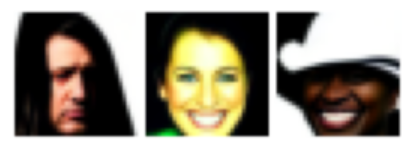